In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Exercício 1

Para cada distribuição abaixo, plote no mesmo gráfico a densidade (ou massa) original $f$ e as versões inclinadas $f_t$ para alguns valores de $t$, positivos e negativos.

1. $N(0, 1)$, com $t \in \{-2, -1, 0, 1, 2\}$
2. $\text{Exp}(1)$, com $t \in \{-1, -0.5, 0, 0.5, 0.75\}$
3. $\text{Gamma}(3, 2)$, com $t \in \{-2, -1, 0, 0.5, 1\}$
4. $\text{Poisson}(4)$, com $t \in \{-1, -0.5, 0, 0.5, 1\}$
5. $\text{Bin}(20, 0.3)$, com $t \in \{-1, -0.5, 0, 0.5, 1\}$

Para cada caso, descreva o efeito do tilt: o que acontece com a média e com a cauda quando $t > 0$ e quando $t < 0$?


### Normal

In [2]:
def densidade_normal(x, mi,sigma2):
    return (1/np.sqrt(2*np.pi*sigma2) * np.exp(-1/(2*sigma2)*(x-mi)**2))

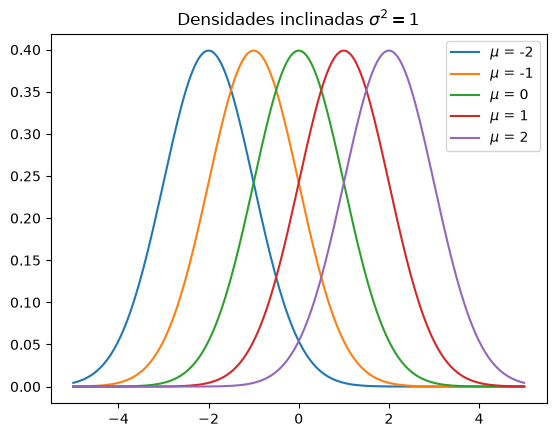

In [3]:
mis = [-2,-1,0,1,2]
x = np.linspace(-5,5, num=200)

plt.title(rf"Densidades inclinadas $\sigma^2 = 1$")
for mi in mis:
    plt.plot(x,densidade_normal(x,mi,1), label=rf'$\mu$ = {mi}')
plt.legend()
plt.show()

### Exponencial

In [4]:
def densidade_exponencial (x, lamb):
    return lamb*np.exp(-lamb*x)

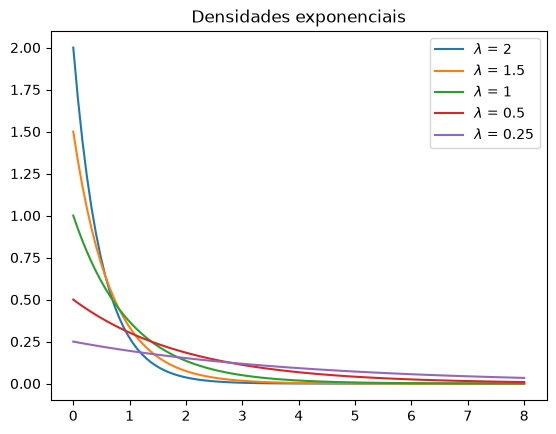

In [5]:
ts = [-1,-.5,0,.5,.75]
x = np.linspace(0,8,100)
plt.title(rf"Densidades exponenciais")
for t in ts:
    plt.plot(x,densidade_exponencial(x,1-t), label = rf'$\lambda$ = {1-t}')
plt.legend()
plt.show()

# Exercício 2

Seja $X \sim N(0,1)$. Queremos estimar

$$
\theta = P(X > 5) \approx 2.87 \times 10^{-7}.
$$

1. **Monte Carlo ingênuo.** Estime $\theta$ amostrando $N = 200{,}000$ valores de $N(0,1)$. Quantas amostras caíram no evento $\{X > 5\}$? A estimativa é confiável?

2. **Escolha da proposta.** Usando o Exercício 1, pense em uma densidade inclinada $f_t$ de $N(0,1)$ que coloque massa na região que importa. Qual valor de $t$ parece razoável? Justifique.

3. **Amostragem por importância.** Amostre de $f_t$ e estime $\theta$ com os pesos $f(x)/f_t(x)$. Compare com o valor exato e com o resultado do item 1.

4. **Sensibilidade a $t$.** Repita o item 3 para alguns valores de $t$, por exemplo $t \in \{1, 3, 5, 7\}$. Compare o erro relativo das estimativas. Qual $t$ funciona melhor, e por quê?


In [29]:
N = 200_000
U = np.random.uniform(size = N) * 2 * np.pi
T = -np.log(np.random.uniform(size = N))

In [32]:
X = np.sqrt(2*T) * np.cos(U)

In [33]:
np.sum(X >= 5)

np.int64(1)

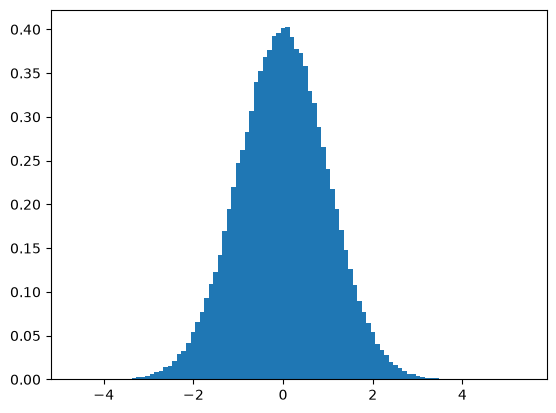

In [34]:
plt.hist(X, density = True, bins = 100)
plt.show()

### 2

In [47]:
Y = X + 5

In [48]:
np.mean((Y >= 5) * densidade_normal(Y,0,1)/densidade_normal(Y,5,1))

np.float64(1.9520728358987295e-07)

# Exercício 3

Seja $X \sim \text{Exp}(1)$. Queremos estimar

$$
\theta = P(X > 20) = e^{-20} \approx 2.06 \times 10^{-9}.
$$

1. **Monte Carlo ingênuo.** Estime $\theta$ com $N = 200{,}000$ amostras de $\text{Exp}(1)$. O que acontece?

2. **Escolha da proposta.** A densidade inclinada de $\text{Exp}(1)$ é $\text{Exp}(1-t)$, com $t < 1$.
   - Para colocar massa perto de $x = 20$, a cauda da proposta deve ficar mais leve ou mais pesada?
   - Qual é o sinal de $t$?
   - Proponha um valor de $t$ de modo que a média da proposta fique em $20$.

3. **Amostragem por importância.** Amostre de $\text{Exp}(1-t)$ e estime $\theta$ com os pesos $f(x)/f_t(x)$. Compare com o valor exato e com o item 1.

4. **Sensibilidade a $t$.** Repita o item 3 para $t \in \{0.5,\ 0.9,\ 0.95,\ 0.99\}$. Compare o erro relativo das estimativas. O que acontece quando $t \to 1$?


## Exercício 4

Seja $X \sim N(0,1)$ e $h(x) = (x - 5)_+ = \max(x - 5,\ 0)$. Queremos estimar

$$
\theta = \mathbb{E}[(X - 5)_+] = \varphi(5) - 5\,\bar\Phi(5) \approx 5.35 \times 10^{-8}.
$$

1. **Visualização.** Plote no mesmo gráfico, para $x \in [-4, 9]$, a densidade $f(x)$, a função $h(x)$ e o produto $h(x)f(x)$, cada um normalizado pelo seu máximo. Onde está concentrada a massa que contribui para $\theta$?

2. **Monte Carlo ingênuo.** Estime $\theta$ com $N = 200{,}000$ amostras de $N(0,1)$. Compare com o valor exato.

3. **Escolha da proposta.** Com base no gráfico, escolha $\lambda$ para a inclinada $f_\lambda = N(\lambda, 1)$. Justifique.

4. **Amostragem por importância.** Estime $\theta$ com o $\lambda$ escolhido e compare o erro relativo com o do item 2.

*Opcional:* calcule numericamente o $\lambda$ que minimiza a variância e compare com $\lambda = 5$, com a moda de $h f$ e com a média de $h f$ normalizada. Qual é a diferença de erro entre essas escolhas?